# Где DeiT сохраняет информацию о классе при изменении масштаба?

В предыдущем [опыте с буквами](scale_operator.ipynb) внешний оператор предсказывал часть изменения CLS даже у случайной сети. Здесь критерий строже — правильный класс объекта. Измеряем его тремя способами: узнавание предмета с другого ракурса, ответ штатной головы на фотографию и ответ после вмешательства в активации. Используем официальные веса DeiT-Tiny/16 для ImageNet-1k с обычным CLS. Перенос весов в тензорную реализацию репозитория проверен относительно независимой реализации torchvision на двух входах (максимальная абсолютная разница логитов 0,000012). [Модель авторов](https://github.com/facebookresearch/deit/blob/main/models.py)

**COIL-20.** В галерее каждый из 20 предметов представлен кадрами одной величины. Задача — узнать этот же физический предмет в другом ракурсе, позиции и масштабе. Из 24 равномерно расположенных ракурсов взяли 12 через один для галереи, остальные для запросов, затем поменяли половины местами. Положения центров в галерее и запросах различаются, фаза относительно сетки 16 × 16 сохраняется. Итого 960 запросов, сгруппированных по 20 предметам. Для каждого предмета усредняем L2-нормированные векторы галереи, нормируем среднее и выбираем ближайший прототип по косинусу. Все прототипы в главном сравнении построены только при 64 px. [Описание COIL-20](https://www.cs.columbia.edu/CAVE/software/softlib/coil-20.php)

Сравниваем CLS и пространственную сетку из 4 × 4 билинейно интерполированных патч-токенов. Обе сетки знают центр кадра. Одна считывает окно фиксированной ширины 64, другая меняет ширину окна вместе с изображением; при 64 они поэлементно совпадают. Точки съёма — после блоков 1, 3, 6, 9, 12 и после финального LayerNorm. Контроли — та же сеть со случайными весами, усреднение 16 патчей до размерности CLS и шаблоны яркости 16 × 16. Главная парная оценка для патчей — разница между окнами на финальном слое при 64→128; разбор по глубине исследовательский.

**Imagenette.** Используем все 500 файлов с исходными именами `ILSVRC2012_val_*.JPEG` из десяти категорий, по 50 на категорию. Исходный валидационный набор ImageNet восстанавливаем из обеих частей переразбитого архива Imagenette-160. Из каждого фото берём один центральный квадрат. Его RGB-версию 64 × 64 либо помещаем на холст 224 × 224, либо интерполируем до 128/224. В качестве ориентира подаём исходный квадрат напрямую при 224. Штатная голова выбирает класс из всех 1000. Каждое сравнение парное по фото, ни один классификатор здесь не дообучается. [Датасет и схема разбиения](https://github.com/fastai/imagenette)

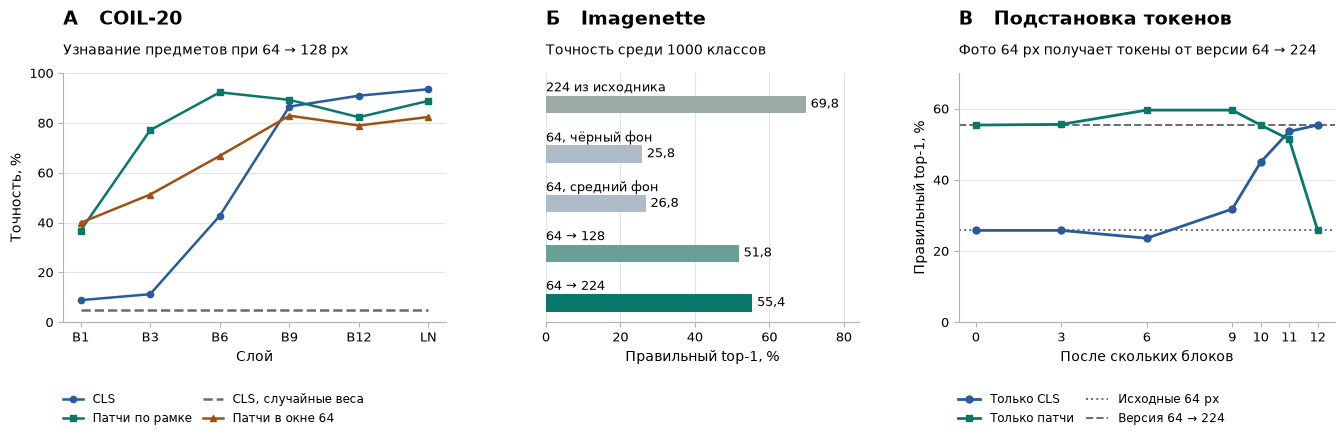

In [1]:
import csv
import sys
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

root = Path.cwd()
if not (root / "experiments/object_readout.py").is_file():
    root = root.parent
sys.path.insert(0, str(root / "experiments"))
from object_figure import make_figure

out = root / "results/object_scale"
def rows(filename):
    with (out / filename).open(encoding="utf-8", newline="") as stream:
        return list(csv.DictReader(stream))

fig = make_figure(out)
plt.show()

### Перенос идентичности на новый ракурс и масштаб

У предобученного DeiT после блока 6 выровненные патчи распознали **886/960** запросов, CLS этого блока — **410/960**. Если усреднить 16 выровненных векторов до тех же 192 координат, что у CLS, остаётся **856/960**. К финальному LayerNorm результат CLS вырос до **898/960** (случайная сеть — **48/960**). Пространственное считывание полезно уже в середине сети; поздний CLS умеет решать эту задачу без передачи ему координат окна.

На финальном слое разница между выровненным и фиксированным окном составила **+6,46 п.п.** (853 против 791 из 960). При парном bootstrap по 20 предметам условный 95% интервал от −3,44 до +18,44 п.п.; пять предметов выиграли, пять проиграли, десять дали равенство. Предметы в галерее и набор конкурентов фиксированы. Выровненный шаблон сырых пикселей сам даёт **864/960**, поэтому высокая точность выровненных патчей на сегментированном COIL допускает простое геометрическое объяснение.

### Что меняет размер при одинаковом исходном растре?

Основное сравнение — низкое разрешение в обоих вариантах. Высокоинформативный ориентир тоже ограничен версией Imagenette-160. На обоих входах меняется масштаб всего фрагмента с окружением; одновременно меняется доля холста, занятая фотографией.

In [2]:
baseline = defaultdict(dict)
targets = {}
for r in rows("imagenette_predictions.csv"):
    image = r["image"]
    assert image not in baseline[r["view"]]
    targets[image] = int(r["target"])
    baseline[r["view"]][image] = int(r["top1"]) == int(r["target"])

images = sorted(targets)
classes = np.array([targets[x] for x in images])
assert len(images) == 500 and set(Counter(classes).values()) == {50}
for condition, values in baseline.items():
    assert set(values) == set(images)
    print(f"{condition:18} {sum(values.values()):3}/500")

small = np.array([baseline["small64_black"][x] for x in images])
large = np.array([baseline["from64_to224"][x] for x in images])
delta = large.astype(int) - small.astype(int)
by_class = np.stack([delta[classes == k] for k in np.unique(classes)])
rng = np.random.default_rng(42)
# Paired resampling of photos within each of the ten fixed categories.
boots = np.stack([rng.choice(d, size=(10000, 50)).mean(1) for d in by_class]).mean(0)
interval = np.quantile(boots, [.025, .975]) * 100
print(f"Исправлено {(delta == 1).sum()}, испорчено {(delta == -1).sum()}")
print(f"Разница {delta.mean()*100:+.1f} п.п., условный 95% интервал [{interval[0]:.1f}, {interval[1]:.1f}]")
print(f"Классов с положительной разницей: {(by_class.mean(1) > 0).sum()}/10")

reference224       349/500
small64_black      129/500
small64_mean       134/500
from64_to128       259/500
from64_to224       277/500
Исправлено 166, испорчено 18
Разница +29.6 п.п., условный 95% интервал [25.2, 34.0]
Классов с положительной разницей: 10/10


Показ того же растра во весь кадр повысил точность с **25,8% до 55,4%** (166 ошибок исправлено, 18 правильных ответов потеряно). Замена чёрной рамки на цвет, близкий к среднему RGB ImageNet, дала **26,8%**. Даже при размере 224 полный исходный фрагмент распознан чаще — **69,8%**. Значит, на этих изображениях важны и режим предъявления, и сохранённая детализация. Цвет рамки объясняет лишь небольшую часть разрыва в проверенной паре вариантов.

### Что изменится, если заменить только CLS или только патчи?

Для каждой фотографии делаем два реальных прогона из одних исходных 64 × 64 пикселей. После выбранного блока сохраняем CLS и все 196 патч-токенов. Собираем гибрид: CLS из большого вида с патчами малого или CLS малого с патчами большого. От этой точки выполняем обычный остаток замороженной сети вместе с исходной головой. В контроле подставляем компонент большой фотографии другого класса. Та же фотография имеет одно и то же смещение и центр в паре. Глубины 10 и 11 добавлены после просмотра первого прогона на глубинах 0, 3, 6, 9, 12.

До первого блока CLS одинаков у всех изображений. За последним блоком голова читает только CLS. Эти крайние точки — проверки реализации, на них результат предопределён. Внутри сети направления замены дают самостоятельные экспериментальные наблюдения.

In [3]:
swaps = rows("imagenette_swaps.csv")
depths = sorted({int(r["depth"]) for r in swaps})
print("Блок   CLS     Патчи    Чужие патчи: верный класс исходника / донора")
for d in depths:
    group = [r for r in swaps if int(r["depth"]) == d]
    def hits(kind, target="target"):
        subset = [r for r in group if r["graft"] == kind]
        assert {r["image"] for r in subset} == set(images) and len(subset) == 500
        return sum(r["top1"] == r[target] for r in subset)
    print(f"{d:4} {hits('same_cls'):5} {hits('same_patches'):9}"
          f" {hits('other_patches'):19} / {hits('other_patches', 'donor_target')}")
assert len(swaps) == len(depths) * 500 * 4

Блок   CLS     Патчи    Чужие патчи: верный класс исходника / донора
   0   129       277                   1 / 277
   3   129       278                   1 / 277
   6   118       298                   1 / 296
   9   159       298                   1 / 295
  10   225       277                   1 / 262
  11   268       257                  46 / 214
  12   277       129                 129 / 0


В блоке 6 патчи увеличенного кадра со старым CLS дали **298/500**, а CLS увеличенного кадра со старыми патчами — **118/500**. Чужие патчи на той же глубине вернули исходную метку **1/500**, метку донора — **296/500**. В таком гибриде банк патчей несёт информацию, специфичную для изображения или его класса. Сам факт, что токены пришли с крупного входа, этого результата не объясняет.

В блоках 9, 10 и 11 перенос только CLS своей фотографии дал **159, 225 и 268** правильных ответов; обратная подстановка патчей — **298, 277 и 257**. В блоке 11 разница между условиями невелика. Отношение меняется постепенно, и после блока 11 оставшийся блок всё ещё может использовать патчи. Гибриды лежат вне обычного распределения активаций, поэтому эти числа говорят о достаточности замен в конкретном вмешательстве.

### Какие выходы внимания способны изменить решение?

После сравнения блоков 9–11 проверяем в блоках 10 и 11 каждую из трёх голов и все три вместе. На вход блока подаём полное состояние малого кадра. Для выбранной головы заменяем только её 64-мерный выход в позиции CLS из прогона увеличенного кадра, после взвешивания значений V и до конкатенации и выходной проекции. На всех остальных позициях сохраняем выходы малого прогона и продолжаем вычисление. Проверяем как донора с той же фотографией, так и увеличенную фотографию другого класса. При совместной замене переносим 192 числа в одном блоке.

In [4]:
head_rows = rows("attention_grafts.csv")
print("Блок  Донор    H0   H1   H2   Все   (верных ответов из 500)")
for block in (10, 11):
    for source in ("same", "other"):
        counts = []
        for h in ("0", "1", "2", "all"):
            subset = [r for r in head_rows if (int(r["block"]), r["source"], r["head"]) == (block, source, h)]
            assert len(subset) == 500 and {r["image"] for r in subset} == set(images)
            counts.append(sum(r["target"] == r["top1"] for r in subset))
        print(f"{block:4}  {source:5}", *(f"{n:4}" for n in counts))

selected = [r for r in head_rows if (r["block"], r["source"], r["head"]) == ("11", "same", "all")]
corrected = {r["image"]: r["target"] == r["top1"] for r in selected}
change = np.array([int(corrected[x]) for x in images]) - small.astype(int)
print(f"Блок 11, три головы: исправлено {(change == 1).sum()}, испорчено {(change == -1).sum()}")

Блок  Донор    H0   H1   H2   Все   (верных ответов из 500)
  10  same   156  153  155  204
  10  other  128  129  103   93
  11  same   160  154  169  208
  11  other  118  122  119   94
Блок 11, три головы: исправлено 90, испорчено 11


Уменьшенный вид сам давал **129/500**. В блоке 11 перенос выходов отдельных голов **своего увеличенного вида** дал **160, 154 и 169**, всех трёх — **208/500**. При переносе всех трёх исправлено 90 ошибок и потеряно 11 правильных ответов. При подстановке от **чужого класса** общая точность упала до **94/500**. У блока 10 наблюдается тот же знак эффекта.

Это вмешательство локализует путь, по которому доступная в большом виде информация влияет на ответ: выходы внимания в позиции CLS двух поздних блоков. Оно требует второго прогона с известным увеличенным видом и переносит вместе с масштабом информацию о содержании. Утверждение о голове, специализированной именно на масштабе, потребовало бы разделить эти факторы.

## Область вывода и воспроизведение

В одной предобученной DeiT-Tiny и на этих масштабах информация для распознавания доступна в пространственных токенах до того, как поздний CLS становится хорошим переносимым признаком. Для изолированных предметов и для естественных сцен протоколы и метки различны. COIL проверяет новые ракурсы уже известных предметов. Imagenette проверяет разные валидационные фотографии в десяти знакомых сети классах; уменьшается весь фрагмент вместе с фоном. Зум камеры, независимое изменение размера объекта на неизменной сцене и произвольная фаза относительно сетки патчей требуют отдельной выборки.

Для пересчёта графика и чисел в ноутбуке достаточно NumPy, Matplotlib и опубликованных CSV. Для полного извлечения нужны PyTorch, Pillow и CUDA. Данные и официальный чекпойнт попадают в игнорируемый кэш, контрольные суммы проверяются при загрузке. Выполнить в корне репозитория:

```sh
python experiments/imagenet_deit.py --download
python experiments/object_tokens.py --download
python experiments/object_readout.py
python experiments/photo_swaps.py --download
python experiments/attention_grafts.py
python experiments/object_figure.py
```